In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Le noyau tourne parfois depuis la racine du projet, parfois depuis notebooks/
DATA = Path("data") if Path("data").exists() else Path("../data")

df = pd.read_csv(DATA / "Mall_Customers.csv")
df.columns = df.columns.str.strip()

features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])
print(df.shape, X_scaled.shape)

(200, 7) (200, 3)


In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

lignes = []
for k in range(4, 9):
    # Modèle de référence (graine 42)
    ref = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_scaled)

    # 30 essais avec d'autres graines, une seule initialisation chacun
    # (n_init=1 pour mesurer la sensibilité à l'initialisation)
    ari, sil = [], []
    for graine in range(30):
        lab = KMeans(n_clusters=k, n_init=1, random_state=graine).fit_predict(X_scaled)
        ari.append(adjusted_rand_score(ref, lab))
        sil.append(silhouette_score(X_scaled, lab))

    lignes.append({
        "k": k,
        "silhouette (réf.)": round(silhouette_score(X_scaled, ref), 3),
        "Davies-Bouldin (bas = mieux)": round(davies_bouldin_score(X_scaled, ref), 3),
        "Calinski-Harabasz (haut = mieux)": round(calinski_harabasz_score(X_scaled, ref), 1),
        "ARI moyen": round(np.mean(ari), 3),
        "ARI min": round(np.min(ari), 3),
        "silhouette min (30 essais)": round(np.min(sil), 3),
    })

resultats = pd.DataFrame(lignes)
display(resultats)

,k,silhouette (réf.),Davies-Bouldin (bas = mieux),Calinski-Harabasz (haut = mieux),ARI moyen,ARI min,silhouette min (30 essais)
0,4,0.404,0.931,125.7,0.876,0.569,0.310
1,5,0.417,0.875,125.1,0.862,0.631,0.353
2,6,0.428,0.825,135.1,0.889,0.651,0.370
3,7,0.417,0.793,132.8,0.812,0.597,0.356
4,8,0.408,0.892,131.0,0.857,0.673,0.385


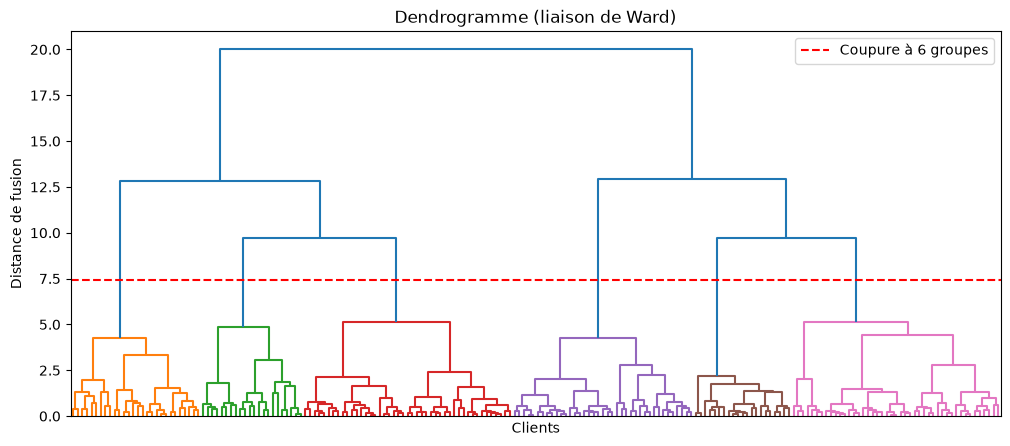

In [3]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Z = linkage(X_scaled, method="ward")
K = 6

plt.figure(figsize=(12, 5))
dendrogram(Z, no_labels=True, color_threshold=(Z[-K, 2] + Z[-(K - 1), 2]) / 2)
plt.axhline((Z[-K, 2] + Z[-(K - 1), 2]) / 2, color="red", linestyle="--", label=f"Coupure à {K} groupes")
plt.title("Dendrogramme (liaison de Ward)")
plt.xlabel("Clients")
plt.ylabel("Distance de fusion")
plt.legend()
plt.show()

In [4]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

lignes = []
for lien in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=K, linkage=lien).fit_predict(X_scaled)
    lignes.append({
        "liaison": lien,
        "silhouette": round(silhouette_score(X_scaled, lab), 3),
        "Davies-Bouldin": round(davies_bouldin_score(X_scaled, lab), 3),
        "Calinski-Harabasz": round(calinski_harabasz_score(X_scaled, lab), 1),
        "effectifs": sorted(np.bincount(lab).tolist()),
    })
display(pd.DataFrame(lignes))

,liaison,silhouette,Davies-Bouldin,Calinski-Harabasz,effectifs
0,ward,0.420,0.852,128.0,"[21, 22, 28, 39, 45, 45]"
1,complete,0.375,1.000,109.4,"[16, 21, 32, 35, 39, 57]"
2,average,0.390,0.865,102.0,"[4, 20, 31, 39, 52, 54]"
3,single,-0.043,0.637,3.5,"[1, 1, 1, 2, 2, 193]"


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

lab_km = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(X_scaled)
lab_hc = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_scaled)

print("ARI K-Means vs hiérarchique (Ward) :", round(adjusted_rand_score(lab_km, lab_hc), 3))
print("\nTableau croisé (lignes = K-Means, colonnes = hiérarchique) :")
display(pd.crosstab(pd.Series(lab_km, name="K-Means"), pd.Series(lab_hc, name="Hiérarchique")))

# Profil moyen de chaque groupe hiérarchique (unités d'origine)
df_tmp = df[features].copy()
df_tmp["Groupe"] = lab_hc
profil = df_tmp.groupby("Groupe").mean().round(1)
profil["Effectif"] = df_tmp["Groupe"].value_counts().sort_index()
display(profil)

# Mémoriser pour le tableau comparatif final (étape A5)
resultats_algos = {}
resultats_algos["K-Means"] = lab_km
resultats_algos["Hiérarchique (Ward)"] = lab_hc

ARI K-Means vs hiérarchique (Ward) : 0.891

Tableau croisé (lignes = K-Means, colonnes = hiérarchique) :


Hiérarchique,0,1,2,3,4,5
K-Means,,,,,,
0,2,43,0,0,0,0
1,39,0,0,0,0,0
2,3,2,0,28,0,0
3,0,0,39,0,0,0
4,1,0,0,0,1,21
5,0,0,0,0,21,0


,Age,Annual Income (k$),Spending Score (1-100),Effectif
Groupe,,,,
0,27.4,57.5,45.8,45
1,56.4,55.3,48.4,45
2,32.7,86.5,82.1,39
3,43.9,91.3,16.7,28
4,44.3,25.8,20.3,22
5,24.8,25.6,80.2,21


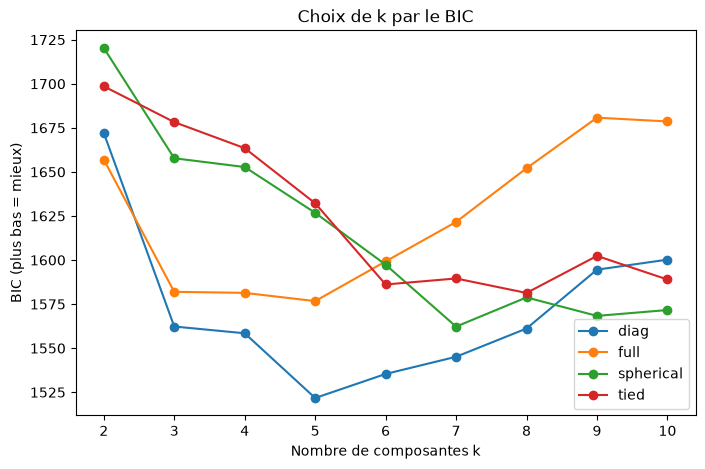

,covariance,k,BIC,AIC
21,diag,5,1521.7,1409.6
22,diag,6,1535.4,1400.1
23,diag,7,1545.1,1386.8
20,diag,4,1558.5,1469.4
24,diag,8,1561.1,1379.7
32,spherical,7,1562.2,1450.1


In [6]:
from sklearn.mixture import GaussianMixture

lignes = []
for cov in ["full", "tied", "diag", "spherical"]:
    for k in range(2, 11):
        g = GaussianMixture(n_components=k, covariance_type=cov, n_init=5, random_state=42).fit(X_scaled)
        lignes.append({"covariance": cov, "k": k, "BIC": g.bic(X_scaled), "AIC": g.aic(X_scaled)})
bic = pd.DataFrame(lignes)

plt.figure(figsize=(8, 5))
for cov, g in bic.groupby("covariance"):
    plt.plot(g["k"], g["BIC"], marker="o", label=cov)
plt.xlabel("Nombre de composantes k")
plt.ylabel("BIC (plus bas = mieux)")
plt.title("Choix de k par le BIC")
plt.legend()
plt.show()

display(bic.sort_values("BIC").head(6).round(1))

Silhouette        : 0.377
Davies-Bouldin    : 0.871
Calinski-Harabasz : 107.6
ARI vs K-Means    : 0.697
ARI vs hiérarchique: 0.654

Confiance moyenne : 0.98
Clients avec confiance < 80 % : 4 sur 200


GMM,0,1,2,3,4,5
K-Means,,,,,,
0,13,0,0,1,30,1
1,0,32,0,0,6,1
2,0,0,0,0,1,32
3,0,0,39,0,0,0
4,0,22,0,1,0,0
5,0,0,0,21,0,0


,Age,Annual Income (k$),Spending Score (1-100),Effectif
Groupe,,,,
0,67.2,55.8,49.8,13
1,25.0,43.5,61.7,54
2,32.7,86.5,82.1,39
3,45.2,26.3,20.9,23
4,49.1,55.1,48.9,37
5,41.6,88.7,16.8,34


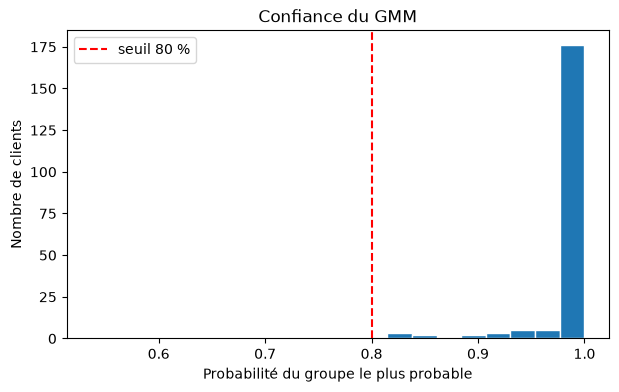

In [7]:
from sklearn.metrics import adjusted_rand_score, silhouette_score, davies_bouldin_score, calinski_harabasz_score

K = 6
gmm = GaussianMixture(n_components=K, covariance_type="full", n_init=10, random_state=42).fit(X_scaled)
lab_gmm = gmm.predict(X_scaled)
proba = gmm.predict_proba(X_scaled)
confiance = proba.max(axis=1)

print("Silhouette        :", round(silhouette_score(X_scaled, lab_gmm), 3))
print("Davies-Bouldin    :", round(davies_bouldin_score(X_scaled, lab_gmm), 3))
print("Calinski-Harabasz :", round(calinski_harabasz_score(X_scaled, lab_gmm), 1))
print("ARI vs K-Means    :", round(adjusted_rand_score(lab_km, lab_gmm), 3))
print("ARI vs hiérarchique:", round(adjusted_rand_score(lab_hc, lab_gmm), 3))
print(f"\nConfiance moyenne : {confiance.mean():.2f}")
print(f"Clients avec confiance < 80 % : {(confiance < 0.8).sum()} sur {len(confiance)}")

display(pd.crosstab(pd.Series(lab_km, name="K-Means"), pd.Series(lab_gmm, name="GMM")))

tmp = df[features].copy()
tmp["Groupe"] = lab_gmm
profil = tmp.groupby("Groupe").mean().round(1)
profil["Effectif"] = tmp["Groupe"].value_counts().sort_index()
display(profil)

plt.figure(figsize=(7, 4))
plt.hist(confiance, bins=20, edgecolor="white")
plt.axvline(0.8, color="red", linestyle="--", label="seuil 80 %")
plt.xlabel("Probabilité du groupe le plus probable")
plt.ylabel("Nombre de clients")
plt.title("Confiance du GMM")
plt.legend()
plt.show()

resultats_algos["GMM"] = lab_gmm

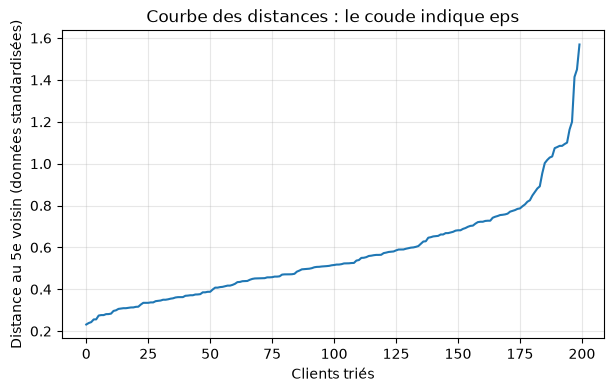

In [8]:
from sklearn.neighbors import NearestNeighbors

ms = 6  # règle usuelle : 2 x nombre de variables
dist, _ = NearestNeighbors(n_neighbors=ms).fit(X_scaled).kneighbors(X_scaled)
kdist = np.sort(dist[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(kdist)
plt.xlabel("Clients triés")
plt.ylabel(f"Distance au {ms-1}e voisin (données standardisées)")
plt.title("Courbe des distances : le coude indique eps")
plt.grid(alpha=0.3)
plt.show()

In [9]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score

lignes = []
for ms_ in [4, 6, 8]:
    for eps in np.round(np.arange(0.3, 1.01, 0.1), 2):
        lab = DBSCAN(eps=eps, min_samples=ms_).fit_predict(X_scaled)
        masque = lab != -1
        n_cl = len(set(lab[masque]))
        sil = (silhouette_score(X_scaled[masque], lab[masque])
               if n_cl >= 2 and masque.sum() > n_cl else np.nan)
        lignes.append({
            "min_samples": ms_,
            "eps": eps,
            "clusters": n_cl,
            "% bruit": round(100 * (~masque).mean(), 1),
            "silhouette (hors bruit)": None if np.isnan(sil) else round(sil, 3),
            "ARI vs K-Means": round(adjusted_rand_score(lab_km, lab), 3),
        })

grille = pd.DataFrame(lignes)
display(grille)

,min_samples,eps,clusters,% bruit,silhouette (hors bruit),ARI vs K-Means
0,4,0.3,7,60.5,0.497,0.099
1,4,0.4,8,36.5,0.458,0.387
2,4,0.5,8,19.5,0.282,0.503
3,4,0.6,3,9.0,0.202,0.195
4,4,0.7,2,4.5,0.176,0.011
5,4,0.8,1,2.5,NaN,0.006
6,4,0.9,1,1.0,NaN,0.002
7,4,1.0,1,0.5,NaN,0.002
8,6,0.3,5,82.0,0.671,-0.002
9,6,0.4,6,55.0,0.558,0.189
